# Do outputs passed around a loop of subjects converge?

| | |
| --- | --- |
| **Question** | When four untrained network subjects pass each output to the next subject in a loop, do runs that begin from different inputs end with similar outputs? |
| **Requires** | CPU only; PyTorch, NumPy, matplotlib. No downloads. A few seconds. |
| **Lessons used** | [1. Your first subject](../lessons/01_your_first_subject.ipynb), [9. Closed loop](../lessons/09_closed_loop.ipynb) |

## Background

Studies of communication between agents connect several systems so that the output of
one becomes the input of the next. A basic property of such a chain is whether it keeps
information about its starting point or forgets it. A chain of random linear-ReLU maps
can contract its inputs, in which case different starting inputs lead to the same output
after a few passes.

The subjects here are small untrained networks. The result describes these networks and
is not a general claim about interacting models.

## Hypothesis

After several rounds through the loop, outputs from runs with different starting inputs
are closer to each other than they were after the first response.

## Method

Each subject is a network with 8 inputs, 16 hidden ReLU units and 8 outputs. Its `policy`
maps the incoming vector to an output vector. Subject 3 uses the same weights as
subject 0, which provides a check that the handoff does not alter the signal.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings('ignore', message='.*__slots__.*', category=FutureWarning)
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from brainscore_core.model_interface import BrainScoreModel
from brainscore.model_helpers.policy_wrapper import PolicyWrapper
from brainscore.harnesses.multi_agent import multi_agent_rollout, DialogueMediator

def make_network(seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(8, 16), nn.ReLU(), nn.Linear(16, 8)).eval()

def make_policy(network):
    def policy(observation, history):
        vector = observation.get('incoming') if isinstance(observation, dict) else observation
        x = torch.as_tensor(np.asarray(vector, 'float32')).reshape(1, -1)
        with torch.no_grad():
            return network(x).squeeze(0).numpy()
    return policy

seeds = [0, 1, 2, 0]
networks = [make_network(s) for s in seeds]
subjects = [BrainScoreModel(identifier=f'subject{i}',
                            policy=PolicyWrapper(policy=make_policy(networks[i]), max_history=4))
            for i in range(4)]

`multi_agent_rollout` runs the loop. A mediator decides what each subject observes;
here the first subject receives a chosen starting vector and every later subject receives
the previous subject's output. Each run has 5 rounds of 4 responses. Subjects are reset
before and after each run so that runs do not share state.

In [2]:
class StartFrom(DialogueMediator):
    def __init__(self, first_input):
        super().__init__(task='pass the signal')
        self.first_input = first_input

    def observe(self, agent_id, incoming):
        return super().observe(agent_id, self.first_input if incoming is None else incoming)

def run_loop(first_input):
    for subject in subjects:
        subject.reset()
    try:
        transcript = multi_agent_rollout(subjects, StartFrom(first_input), n_turns=5)
        return np.stack([entry['action'] for entry in transcript])
    finally:
        for subject in subjects:
            subject.reset()

starts = np.random.RandomState(100).randn(12, 8).astype('float32')
runs = np.stack([run_loop(start) for start in starts])   # (12 runs, 20 responses, 8 values)
print('runs:', runs.shape)

runs: (12, 20, 8)


The next cell checks every handoff. Each response must equal the receiving network
applied directly to the previous response, and subject 3's responses must equal subject
0's network applied to the same input.

In [3]:
for responses in runs:
    for step in range(1, len(responses)):
        receiver = step % len(subjects)
        incoming = {'incoming': responses[step - 1]}
        np.testing.assert_array_equal(make_policy(networks[receiver])(incoming, None), responses[step])
        if receiver == 3:
            np.testing.assert_array_equal(make_policy(networks[0])(incoming, None), responses[step])
print('all handoffs verified')

all handoffs verified


The spread across runs is measured as each run's Euclidean distance from the mean
response across the 12 runs, at each of the 20 response positions.

In [4]:
distances = np.linalg.norm(runs - runs.mean(axis=0, keepdims=True), axis=2)
steps = np.arange(1, runs.shape[1] + 1)

## Results

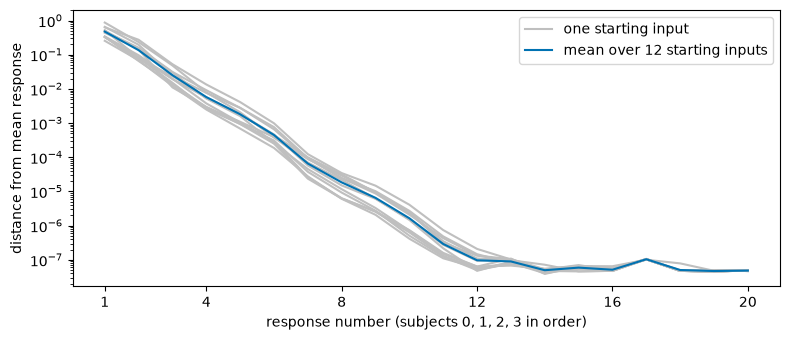

mean distance after response 1: 0.476; after response 20: 4.86e-08


In [5]:
floor = 1e-8   # values below this are drawn at the floor on the log axis
fig, ax = plt.subplots(figsize=(8, 3.5))
for i, distance in enumerate(distances):
    ax.plot(steps, np.maximum(distance, floor), color='0.75',
            label='one starting input' if i == 0 else None)
ax.plot(steps, np.maximum(distances.mean(axis=0), floor), color='#0072B2',
        label='mean over 12 starting inputs')
ax.set_yscale('log')
ax.set_xlabel('response number (subjects 0, 1, 2, 3 in order)')
ax.set_ylabel('distance from mean response')
ax.set_xticks([1, 4, 8, 12, 16, 20])
ax.legend()
fig.tight_layout()
plt.show()
print(f'mean distance after response 1: {distances[:, 0].mean():.3g}; '
      f'after response 20: {distances[:, -1].mean():.3g}')

The mean distance from the across-run mean falls from 0.476 after the first
response to about 5e-8 after the twentieth, which is close to floating-point precision.

## Conclusion and limits

For these 12 starting inputs, the outputs of the untrained loop become more similar as
they pass through the subjects, so the loop loses information about where it started.
This is a property of these particular random networks; trained networks, other
architectures or other starting inputs may behave differently.

The experiment uses only the subjects' outputs. Comparing the internal representations of
interacting subjects, for example with representational similarity analysis, would
require recording their activations during the loop.

[Lessons](../lessons/) · [Documentation](../../docs/README.md)